In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from skimage.feature import hog
from skimage import exposure

# Locate project directory
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_DIR = CURRENT_DIR.parent
elif (CURRENT_DIR / "data" / "images").exists():
    PROJECT_DIR = CURRENT_DIR
else:
    PROJECT_DIR = CURRENT_DIR.parent

IMAGE_PATH = PROJECT_DIR / "data" / "images" / "original.jpeg"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "task2_feature_matching"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load original image
image_bgr = cv2.imread(str(IMAGE_PATH))

if image_bgr is None:
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH.resolve()}")

image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

print("Image loaded:", image.shape)
print("Output directory:", OUTPUT_DIR.resolve())

Image loaded: (1280, 721, 3)
Output directory: D:\Projects\CV\outputs\task2_feature_matching


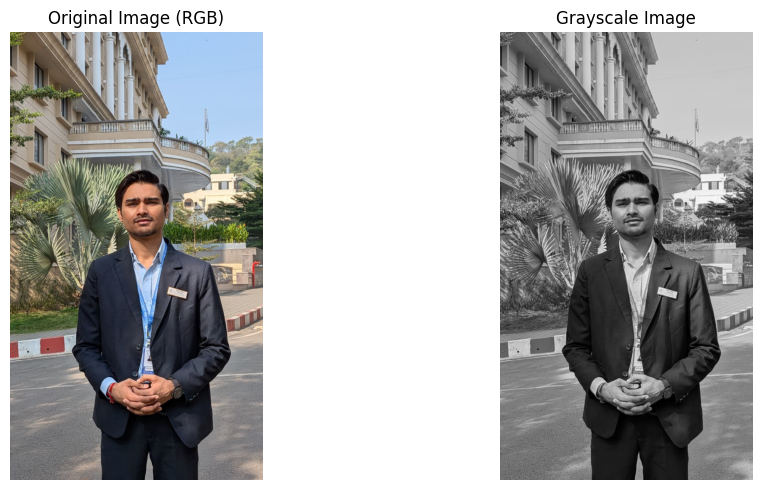

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(image)
ax[0].set_title("Original Image (RGB)")
ax[1].imshow(gray, cmap="gray")
ax[1].set_title("Grayscale Image")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_original_and_grayscale.png",
            dpi=150, bbox_inches="tight")
plt.show()

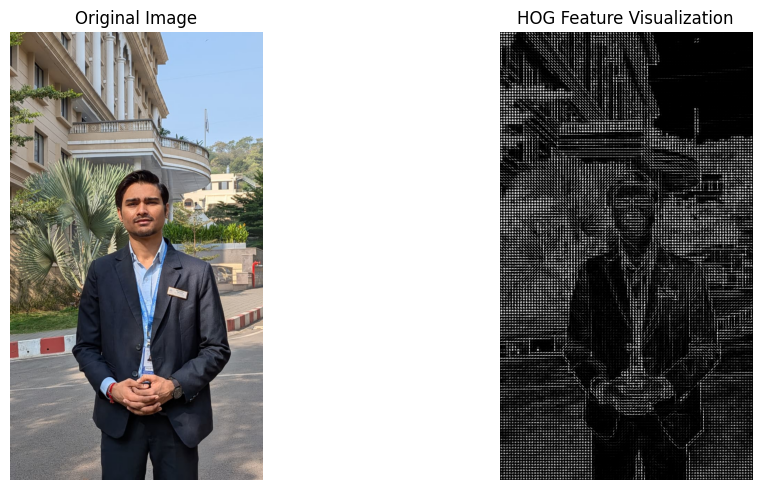

HOG descriptor length: 509436


In [3]:
hog_features, hog_image = hog(
    gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True
)

hog_visual = exposure.rescale_intensity(
    hog_image, in_range=(0, 10)
)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(image)
ax[0].set_title("Original Image")

ax[1].imshow(hog_visual, cmap="gray")
ax[1].set_title("HOG Feature Visualization")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_hog_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()

print("HOG descriptor length:", len(hog_features))

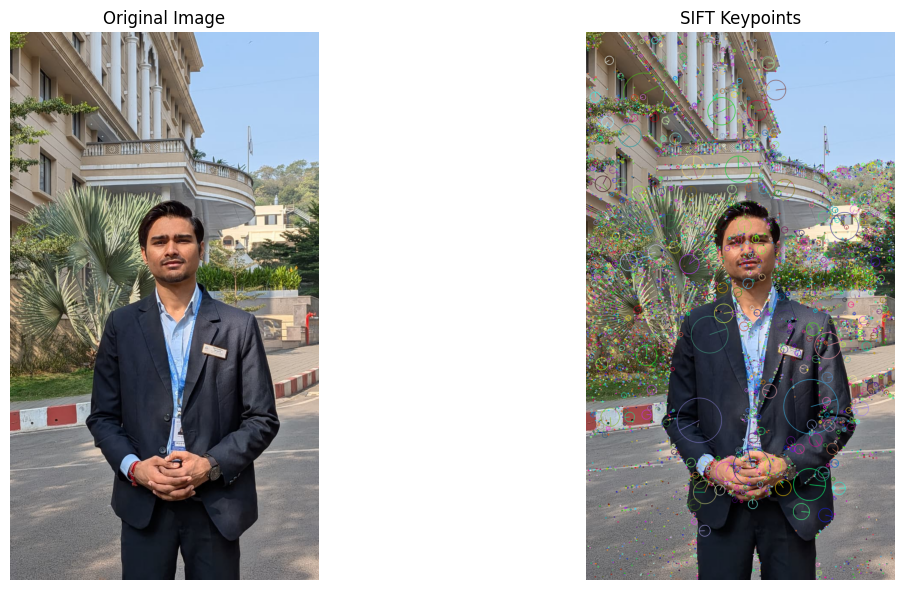

SIFT keypoints detected: 7446
Descriptor matrix shape: (7446, 128)


In [4]:
sift = cv2.SIFT_create()

keypoints, descriptors = sift.detectAndCompute(gray, None)

# Draw detected keypoints
sift_image = cv2.drawKeypoints(
    image,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(image)
ax[0].set_title("Original Image")

ax[1].imshow(sift_image)
ax[1].set_title("SIFT Keypoints")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_sift_keypoints.png",
            dpi=150, bbox_inches="tight")
plt.show()

print("SIFT keypoints detected:", len(keypoints))

if descriptors is not None:
    print("Descriptor matrix shape:", descriptors.shape)
else:
    print("No SIFT descriptors were found.")

In [5]:
# Save HOG descriptor
np.save(OUTPUT_DIR / "hog_features.npy", hog_features)

# Save SIFT descriptors if available
if descriptors is not None:
    np.save(OUTPUT_DIR / "sift_descriptors.npy", descriptors)

# Save keypoint visualization
cv2.imwrite(
    str(OUTPUT_DIR / "04_sift_keypoints_saved.png"),
    cv2.cvtColor(sift_image, cv2.COLOR_RGB2BGR)
)

print("Feature data and visualization saved successfully.")

Feature data and visualization saved successfully.


## Observations

- HOG extracts gradient-based features that describe local shapes and edges.
- SIFT identifies distinctive keypoints and calculates descriptors for them.
- The number of SIFT keypoints depends on image texture, resolution, and contrast.
- Matching quality cannot yet be evaluated because only one image is being used.
  A second photograph is required to perform and compare feature matches.